# آزمایش BERT Mini: ورودی ۲۵۶ توکن، summary برای متن بلند، batch=128

این نسخه را در **Colab با GPU نوع T4** اجرا کنید. نصب کتابخانه‌ها در runtime تازه انجام شود؛ پس از import قبلی کتابخانه‌ها، session را restart کنید.

معماری همان `google/bert_uncased_L-4_H-256_A-4` با ۴ لایه، hidden size=256، ۴ سر attention و خروجی ۵کلاسه است؛ تمام وزن‌ها fine-tune می‌شوند. Learning rate برابر `2e-5`، حداکثر ۴ epoch، early stopping با patience=2 و انتخاب بهترین Validation Micro-F1 حفظ شده‌اند. Accuracy و Micro-F1 در این مسئله تک‌برچسبی برابرند؛ Macro-F1 و MAE نیز ثبت می‌شوند.

**قاعده ورودی، دقیق و یکسان در آموزش و پیش‌بینی:**

- اگر reviewText با توکن‌های ویژه در ۲۵۶ توکن جا شود، فقط خود reviewText استفاده می‌شود؛ summary وارد این نمونه نمی‌شود.
- اگر reviewText بلندتر باشد، متن `summary + " " + reviewText` توکن‌سازی می‌شود. summary خالی به معنی استفاده از خود reviewText است. از دنباله دارای توکن‌های ویژه، **۱۹۲ توکن اول و ۶۴ توکن آخر** نگه داشته می‌شود. بنابراین ورودی نهایی `[CLS] + 191 توکن ابتدایی متن + 63 توکن انتهایی متن + [SEP]` و دقیقاً ۲۵۶ توکن است. توکن‌های ویژه در سهم ۱۹۲/۶۴ حساب شده‌اند.
- Padding فقط هنگام ساخت batch و تا بلندترین نمونه همان batch انجام می‌شود، با گرد کردن طول به مضرب ۸ و attention mask صحیح. کلمات منفی، stop wordها و نشانه‌گذاری حذف نمی‌شوند.

**داده و ارزیابی:** ابتدا نصف کل داده معتبر با حفظ توزیع کلاس‌ها، سپس تقسیم ۷۰/۱۵/۱۵. برای همان عضویت ردیف‌های خط مبنای قبلی، مسیر اجرای آن را در `BASELINE_RUN_DIR` یا مسیر splits آن را در `REUSE_SPLITS_DIR` قرار دهید. summary با source_row_id به ردیف‌های ذخیره‌شده متصل می‌شود؛ افزودن summary عضویت splitها را تغییر نمی‌دهد. Validation کامل پس از هر epoch انجام می‌شود و Test با `RUN_TEST=False` برای پایان توسعه نگه داشته شده است.

**T4:** batch واقعی آموزش ۱۲۸، gradient accumulation برابر ۱، batch ارزیابی ۱۲۸، FP16، padding مضرب ۸ و pinned memory فعال‌اند. BF16 خاموش است. Batch بزرگ‌تر تعداد optimizer stepها را کم می‌کند؛ ورودی بلندتر محاسبات بیشتری دارد و افزایش سرعت خالص باید اندازه‌گیری شود. حافظه کافی برای batch=128 هنگام اجرای واقعی مشخص می‌شود. در خطای OOM، تغییر صریح به batch=64 و accumulation=2 batch مؤثر ۱۲۸ را حفظ می‌کند؛ تنظیم واقعی را همراه نتیجه گزارش کنید.

این اجرا اثر مجموع **طول ورودی، summary/head-tail و batch** را اندازه می‌گیرد. برای سهم مستقل هر تغییر، آن‌ها را در اجراهای جدا عوض کنید. سرعت و نتیجه واقعی پس از اجرای داده روی GPU ثبت می‌شوند.


In [1]:
%pip install -q "transformers==4.57.1" "datasets>=3,<5" "accelerate>=1,<2" scikit-learn gdown pyarrow matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## ۱. دریافت و خواندن داده
روش دریافت و خواندن فایل از نسخه اولیه حفظ شده است.


In [2]:
from pathlib import Path
import gdown

DATA_DIR = Path("/content/amazon_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

FILE_ID = "1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW"

# Preserve the original filename and extension.
downloaded_path = gdown.download(
    id=FILE_ID,
    output=str(DATA_DIR) + "/",
    quiet=False,
)

if downloaded_path is None:
    raise RuntimeError("Download failed. Check the file's sharing permissions.")

data_path = Path(downloaded_path)

print("Filename:", data_path.name)
print(f"File size: {data_path.stat().st_size / (1024**2):,.1f} MB")


Downloading...
From (original): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW
From (redirected): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW&confirm=t&uuid=2c630c2d-a424-4f65-8b66-8e51957fa6bb
To: /content/amazon_data/train_data.csv
100%|██████████| 635M/635M [00:03<00:00, 184MB/s]

Filename: train_data.csv
File size: 605.2 MB


In [3]:
import gzip
import json
import zipfile

import pandas as pd
from IPython.display import display

KEEP_COLUMNS = ["reviewText", "summary", "overall"]


def read_reviews(stream, filename):
    name = filename.lower()

    if name.endswith(".csv"):
        return pd.read_csv(
            stream,
            usecols=lambda column: column in KEEP_COLUMNS,
        )

    if name.endswith((".json", ".jsonl", ".ndjson")):
        # Inspect the first line to distinguish JSON Lines from a JSON array.
        first_line = stream.readline().strip()
        stream.seek(0)

        if first_line.startswith(b"["):
            frame = pd.read_json(stream)
            return frame.loc[:, frame.columns.intersection(KEEP_COLUMNS)]

        try:
            first_record = json.loads(first_line)
            is_json_lines = isinstance(first_record, dict)
        except json.JSONDecodeError:
            is_json_lines = False

        if is_json_lines:
            # Read in chunks to reduce temporary memory usage.
            chunks = pd.read_json(stream, lines=True, chunksize=50_000)
            frames = [
                chunk.loc[:, chunk.columns.intersection(KEEP_COLUMNS)]
                for chunk in chunks
            ]
            return pd.concat(frames, ignore_index=True)

        frame = pd.read_json(stream)
        return frame.loc[:, frame.columns.intersection(KEEP_COLUMNS)]

    raise ValueError(f"Unsupported file format: {filename}")


if zipfile.is_zipfile(data_path):
    with zipfile.ZipFile(data_path) as archive:
        candidates = [
            name for name in archive.namelist()
            if not name.startswith("__MACOSX/")
            and name.lower().endswith((".csv", ".json", ".jsonl", ".ndjson"))
        ]

        if len(candidates) != 1:
            raise ValueError(
                f"Expected one data file inside ZIP. Found: {candidates}"
            )

        with archive.open(candidates[0]) as stream:
            df = read_reviews(stream, candidates[0])

elif data_path.name.lower().endswith(".gz"):
    with gzip.open(data_path, "rb") as stream:
        df = read_reviews(stream, data_path.stem)

else:
    with data_path.open("rb") as stream:
        df = read_reviews(stream, data_path.name)

required_columns = {"reviewText", "overall"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print(f"Number of reviews: {len(df):,}")
print("Loaded columns:", df.columns.tolist())
display(df.head())


Number of reviews: 838,944
Loaded columns: ['overall', 'reviewText', 'summary']


,overall,reviewText,summary
0,2,I have an older URC-WR7 remote and thought thi...,Cannot Learn
1,5,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?
2,4,Got them and only 2 of them worked. company ca...,Works Good and programs easy.
3,5,I got tired of the remote being on the wrong s...,Same as TWC remote
4,5,After purchasing cheap cords from another webs...,Good Quality Cord


## ۲. تنظیمات ثابت آزمایش
برای مقایسه معماری‌ها، این تنظیمات و splitها را ثابت نگه دارید. هر اجرا پوشه مجزا دارد.


In [4]:
import os, json, hashlib, shutil, time, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import transformers, datasets, sklearn
from sklearn.model_selection import train_test_split
from transformers import set_seed
from google.colab import drive

SEED = 42
MODEL_NAME = "google/bert_uncased_L-4_H-256_A-4"
MAX_LENGTH = 256
HEAD_TOKENS = 192
TAIL_TOKENS = 64
TRAIN_BATCH_SIZE = 128
GRADIENT_ACCUMULATION_STEPS = 1
EVAL_BATCH_SIZE = 128
EPOCHS = 4
LEARNING_RATE = 2e-5
RUN_TEST = False  # Enable only after the model-development decisions are final.
# Example: '/content/drive/MyDrive/amazon_sentiment/half_data_baselines/OLD_RUN_ID'
BASELINE_RUN_DIR = None  # Existing 128-token run; enables splits reuse and comparison.
REUSE_SPLITS_DIR = None  # Alternatively, set the previous run's 'splits' directory.
if BASELINE_RUN_DIR is not None and REUSE_SPLITS_DIR is None:
    REUSE_SPLITS_DIR = str(Path(BASELINE_RUN_DIR)/'splits')

set_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Select Runtime > Change runtime type > GPU in Colab.")
drive.mount('/content/drive')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
LOCAL_RUN_DIR = Path('/content/amazon_256_runs') / RUN_ID
RUN_DIR = Path('/content/drive/MyDrive/amazon_sentiment/experiments_256') / RUN_ID
SPLITS_DIR = RUN_DIR / 'splits'
CHECKPOINT_DIR = LOCAL_RUN_DIR / 'checkpoints'
for directory in [LOCAL_RUN_DIR, RUN_DIR, SPLITS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0))
print('Results:', RUN_DIR)

print('Physical training batch:', TRAIN_BATCH_SIZE)
print('Effective training batch:', TRAIN_BATCH_SIZE*GRADIENT_ACCUMULATION_STEPS)
if 'T4' not in torch.cuda.get_device_name(0):
    print('This run was configured for T4; the detected GPU is recorded in the results.')


Mounted at /content/drive
GPU: Tesla T4
Results: /content/drive/MyDrive/amazon_sentiment/experiments_256/20261104_160755_670535
Physical training batch: 128
Effective training batch: 128


## ۳. پاک‌سازی، انتخاب نصف داده و تقسیم stratified
شناسه ردیف اصلی پیش از reset index نگه داشته می‌شود. این تقسیم در سطح ردیف است؛ برای تعمیم به کاربران یا محصولات جدید به آزمایشی با تقسیم گروهی نیاز است. متن‌های تکراری احتمالی حذف نمی‌شوند تا پروتکل پاک‌سازی اولیه حفظ شود؛ میزان هم‌پوشانی متن‌ها گزارش می‌شود.


In [5]:
if 'summary' not in df.columns:
    raise ValueError("The input file must include 'summary' for this experiment.")
# Keep the BASELINE fingerprint independent of the newly added input feature.
summary_by_id = df['summary'].fillna('').astype(str).str.strip().reset_index(drop=True)
data = df[['reviewText', 'overall']].copy()
data['source_row_id'] = np.arange(len(data), dtype=np.int64)
data['overall'] = pd.to_numeric(data['overall'], errors='coerce')
data['reviewText'] = data['reviewText'].astype('string').str.strip()
valid = (data['overall'].isin([1,2,3,4,5]) & data['reviewText'].notna()
         & data['reviewText'].ne('')).fillna(False)
data = data.loc[valid].copy()
data['overall'] = data['overall'].astype('int64')
data['labels'] = data['overall'] - 1
data = data.reset_index(drop=True)
# Include cleaned text, labels and row identity in the data fingerprint.
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(data, index=False).values.tobytes()
).hexdigest()

if REUSE_SPLITS_DIR is None:
    selected_df, _ = train_test_split(
        data, train_size=0.5, stratify=data['labels'], random_state=SEED)
    train_df, remaining = train_test_split(
        selected_df, test_size=0.30,
        stratify=selected_df['labels'], random_state=SEED)
    val_df, test_df = train_test_split(
        remaining, test_size=0.50, stratify=remaining['labels'], random_state=SEED)
else:
    old_dir = Path(REUSE_SPLITS_DIR)
    previous = json.loads((old_dir/'split_manifest.json').read_text())
    assert previous['data_fingerprint'] == fingerprint, 'Input data changed.'
    assert previous['seed'] == SEED, 'Split seed changed.'
    train_df, val_df, test_df = [pd.read_parquet(old_dir/f'{s}.parquet')
                                for s in ['train','validation','test']]
    # Verify saved rows against current input before attaching summaries.
    current = data.set_index('source_row_id')
    for frame in [train_df, val_df, test_df]:
        saved_ids = frame['source_row_id'].to_numpy()
        expected = current.loc[saved_ids]
        assert np.array_equal(expected['labels'].to_numpy(), frame['labels'].to_numpy())
        assert np.array_equal(expected['reviewText'].to_numpy(), frame['reviewText'].to_numpy())
    selected_df = pd.concat([train_df,val_df,test_df], ignore_index=True)

# Copies avoid chained assignment and preserve the stored row order.
train_df, val_df, test_df = [f.copy() for f in [train_df, val_df, test_df]]
for frame in [train_df, val_df, test_df]:
    frame['summary'] = summary_by_id.iloc[frame['source_row_id'].to_numpy()].to_numpy()
split_frames = {'train': train_df, 'validation': val_df, 'test': test_df}
id_sets = [set(f['source_row_id']) for f in split_frames.values()]
assert all(len(ids)==len(frame) for ids,frame in zip(id_sets,split_frames.values()))
assert all(id_sets[i].isdisjoint(id_sets[j]) for i,j in [(0,1),(0,2),(1,2)])
assert sum(map(len,split_frames.values())) == len(data)//2
split_fingerprint = hashlib.sha256(b''.join(
    np.sort(f['source_row_id'].to_numpy(dtype=np.int64)).tobytes()
    for f in split_frames.values())).hexdigest()
for name, frame in split_frames.items():
    frame.reset_index(drop=True).to_parquet(SPLITS_DIR/f'{name}.parquet', index=False)
manifest = {'seed': SEED, 'data_fingerprint':fingerprint,
            'split_fingerprint':split_fingerprint, 'sampling_fraction':0.5,
            'ratios':[0.70,0.15,0.15],
            'sizes':{name:len(f) for name,f in split_frames.items()},
            'summary_fingerprint': hashlib.sha256(pd.util.hash_pandas_object(
                summary_by_id, index=False).values.tobytes()).hexdigest()}
(SPLITS_DIR/'split_manifest.json').write_text(json.dumps(manifest,indent=2))
def percentages(frame):
    return frame['overall'].value_counts(normalize=True).reindex(range(1,6),fill_value=0)*100
display(pd.DataFrame({'All usable (%)':percentages(data),
                      'Selected half (%)':percentages(selected_df),
                      **{name+' (%)':percentages(f) for name,f in split_frames.items()}}).round(3))
print('Usable:',len(data), '| Selected:',len(selected_df))
print('Sizes:', manifest['sizes'])
print('Reuse these splits:', SPLITS_DIR)
text_sets = {name:set(f['reviewText']) for name,f in split_frames.items()}
duplicate_overlap = {f'{a} vs {b}':len(text_sets[a]&text_sets[b])
    for a,b in [('train','validation'),('train','test'),('validation','test')]}
print('Number of distinct identical texts shared between splits:',duplicate_overlap)
(RUN_DIR/'duplicate_text_overlap.json').write_text(json.dumps(duplicate_overlap,indent=2))
del text_sets, df, data, selected_df, summary_by_id


,All usable (%),Selected half (%),train (%),validation (%),test (%)
overall,,,,,
1,9.887,9.887,9.887,9.887,9.889
2,6.765,6.765,6.765,6.766,6.764
3,9.683,9.683,9.683,9.684,9.684
4,18.656,18.656,18.656,18.655,18.657
5,55.008,55.008,55.008,55.009,55.007


Usable: 838944 | Selected: 419472
Sizes: {'train': 293630, 'validation': 62921, 'test': 62921}
Reuse these splits: /content/drive/MyDrive/amazon_sentiment/experiments_256/20261104_160755_670535/splits
Number of distinct identical texts shared between splits: {'train vs validation': 1732, 'train vs test': 1714, 'validation vs test': 386}


## ۴. توکن‌سازی و معماری اصلی
Test در طول توسعه توکن‌سازی و ارزیابی نمی‌شود. Padding هر batch تا طول بلندترین نمونه همان batch، با مضرب ۸ انجام می‌شود.


In [6]:
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
set_seed(SEED)  # Reproduce the randomly initialized classification head.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=5,
    id2label={i:str(i+1) for i in range(5)},
    label2id={str(i+1):i for i in range(5)})
for parameter in model.parameters():
    parameter.requires_grad = True
assert model.config.num_hidden_layers == 4
assert model.config.hidden_size == 256
assert model.config.num_attention_heads == 4
print('Parameters:',format(sum(p.numel() for p in model.parameters()),','))

SPECIAL_TOKENS = tokenizer.num_special_tokens_to_add(pair=False)
assert SPECIAL_TOKENS == 2
assert HEAD_TOKENS + TAIL_TOKENS == MAX_LENGTH
CONTENT_LIMIT = MAX_LENGTH - SPECIAL_TOKENS
HEAD_CONTENT = HEAD_TOKENS - 1  # [CLS] belongs to the head segment.
TAIL_CONTENT = TAIL_TOKENS - 1  # [SEP] belongs to the tail segment.

PREPROCESSING_CONFIG = {
    'max_length':MAX_LENGTH, 'head_tokens_with_cls':HEAD_TOKENS,
    'tail_tokens_with_sep':TAIL_TOKENS, 'short_input':'reviewText_only',
    'long_input':'summary + single_space + reviewText',
    'long_review_threshold_content_tokens':CONTENT_LIMIT,
    'dynamic_padding':True, 'pad_to_multiple_of':8,
}

def select_content_ids(review_ids, combined_ids=None):
    # Operate on token IDs; decoding/re-encoding can change token boundaries.
    if len(review_ids) <= CONTENT_LIMIT:
        return list(review_ids)
    if combined_ids is None or len(combined_ids) <= CONTENT_LIMIT:
        raise ValueError('A long review requires the complete combined token IDs.')
    return list(combined_ids[:HEAD_CONTENT]) + list(combined_ids[-TAIL_CONTENT:])

def wrap_content_ids(content_ids):
    input_ids = tokenizer.build_inputs_with_special_tokens(content_ids)
    token_type_ids = tokenizer.create_token_type_ids_from_sequences(content_ids)
    assert len(input_ids) <= MAX_LENGTH
    return {'input_ids':input_ids, 'attention_mask':[1]*len(input_ids),
            'token_type_ids':token_type_ids}

def tokenize_batch(batch):
    reviews = [str(text).strip() for text in batch['reviewText']]
    summaries = [str(text).strip() for text in batch['summary']]
    review_ids = tokenizer(reviews, add_special_tokens=False, truncation=False,
                           padding=False, verbose=False)['input_ids']
    # Only long reviews need a second tokenization with their summaries.
    long_indices = [i for i, ids in enumerate(review_ids) if len(ids)>CONTENT_LIMIT]
    combined_by_index = {}
    if long_indices:
        combined = [(summaries[i]+' '+reviews[i]).strip() for i in long_indices]
        combined_ids = tokenizer(combined, add_special_tokens=False, truncation=False,
                                 padding=False, verbose=False)['input_ids']
        combined_by_index = dict(zip(long_indices, combined_ids))
    output = {'input_ids':[], 'attention_mask':[], 'token_type_ids':[]}
    for i, ids in enumerate(review_ids):
        example = wrap_content_ids(select_content_ids(ids, combined_by_index.get(i)))
        for key in output:
            output[key].append(example[key])
    return output

raw_datasets = DatasetDict({name:Dataset.from_pandas(
    frame[['reviewText','summary','labels']],preserve_index=False)
    for name,frame in [('train',train_df),('validation',val_df)]})
tokenized_datasets = raw_datasets.map(
    tokenize_batch, batched=True, batch_size=256,
    remove_columns=['reviewText','summary'], desc='Tokenizing 256-token head-tail inputs')
data_collator = DataCollatorWithPadding(tokenizer=tokenizer,pad_to_multiple_of=8)
print(tokenized_datasets)

# Boundary checks use the actual tokenizer; these do not train the model.
assert select_content_ids(list(range(254)), [999]*400) == list(range(254))
synthetic_review = list(range(255))
synthetic_combined = list(range(500))
selected = select_content_ids(synthetic_review, synthetic_combined)
assert selected == synthetic_combined[:191] + synthetic_combined[-63:]
assert len(wrap_content_ids(selected)['input_ids']) == 256
example_batch = tokenize_batch({
    'reviewText':['good product', 'good '*254, 'good '*255, 'bad '*400],
    'summary':['ignored summary', 'ignored summary', 'excellent', ''],
})
lengths = [len(ids) for ids in example_batch['input_ids']]
assert lengths[0] < 256 and lengths[1:] == [256,256,256]
assert example_batch['input_ids'][0] == tokenizer('good product')['input_ids']
expected_combined = tokenizer('excellent '+'good '*255,
                              add_special_tokens=False)['input_ids']
assert example_batch['input_ids'][2] == tokenizer.build_inputs_with_special_tokens(
    expected_combined[:191]+expected_combined[-63:])
padded = data_collator([{key:value[i] for key,value in example_batch.items()}
                        for i in range(4)])
assert padded['input_ids'].shape == (4,256)
assert padded['attention_mask'].sum(dim=1).tolist() == lengths
print('Token selection, boundary cases and dynamic-padding checks passed.')
del padded


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-4_H-256_A-4 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parameters: 11,171,845


model.safetensors:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

Tokenizing 256-token head-tail inputs:   0%|          | 0/293630 [00:00<?, ? examples/s]

Tokenizing 256-token head-tail inputs:   0%|          | 0/62921 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask', 'token_type_ids'],
        num_rows: 293630
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask', 'token_type_ids'],
        num_rows: 62921
    })
})
Token selection, boundary cases and dynamic-padding checks passed.


## ۵. معیارها و تنظیم آموزش
Validation کامل است: تمام ردیف‌ها در هر بار ارزیابی بررسی می‌شوند. ذخیره و ارزیابی هر دو در پایان epoch انجام می‌شوند تا بهترین checkpoint درست انتخاب و بارگذاری شود. Early stopping معیار Micro-F1 را دنبال می‌کند.


In [7]:
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             classification_report, confusion_matrix)
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback, TrainerCallback

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    if isinstance(logits,tuple):
        logits = logits[0]
    predictions = np.argmax(logits,axis=-1)
    return {
        'micro_f1':f1_score(labels,predictions,labels=list(range(5)),average='micro',zero_division=0),
        'macro_f1':f1_score(labels,predictions,labels=list(range(5)),average='macro',zero_division=0),
        'accuracy':accuracy_score(labels,predictions),
        'mae':mean_absolute_error(labels,predictions),
    }

class DriveBackupCallback(TrainerCallback):
    def on_save(self,args,state,control,**kwargs):
        # Copy only after a complete local checkpoint has been written.
        source = Path(args.output_dir)/f'checkpoint-{state.global_step}'
        target = RUN_DIR/'checkpoints'/source.name
        shutil.copytree(source,target,dirs_exist_ok=True)
        best_name = Path(state.best_model_checkpoint).name if state.best_model_checkpoint else None
        for old in target.parent.glob('checkpoint-*'):
            if old.name not in {target.name,best_name}:
                shutil.rmtree(old)
        pd.DataFrame(state.log_history).to_csv(RUN_DIR/'training_history.csv',index=False)
        return control

# T4 uses FP16 mixed precision for this experiment.
training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=EPOCHS, learning_rate=LEARNING_RATE,
    weight_decay=0.01, warmup_ratio=0.06, lr_scheduler_type='linear',
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    fp16=True, bf16=False,
    optim='adamw_torch',
    eval_strategy='epoch', save_strategy='epoch', save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model='micro_f1',
    greater_is_better=True,
    logging_strategy='steps',logging_steps=200,report_to='none',
    seed=SEED,data_seed=SEED,
    dataloader_num_workers=2,dataloader_pin_memory=True,
    dataloader_persistent_workers=True,dataloader_drop_last=False,
)
config = {
    'run_id':RUN_ID,'model':MODEL_NAME,'max_length':MAX_LENGTH,
    'train_batch':TRAIN_BATCH_SIZE,'eval_batch':EVAL_BATCH_SIZE,
    'gradient_accumulation_steps':GRADIENT_ACCUMULATION_STEPS,'epochs_max':EPOCHS,
    'effective_train_batch':TRAIN_BATCH_SIZE*GRADIENT_ACCUMULATION_STEPS,
    'preprocessing':PREPROCESSING_CONFIG,
    'summary_fingerprint':manifest['summary_fingerprint'],
    'selection_metric':'micro_f1','early_stopping_patience':2,
    'seed':SEED,'split_fingerprint':split_fingerprint,
    'gpu':torch.cuda.get_device_name(0),
    'versions':{'python':platform.python_version(),'torch':torch.__version__,
                'transformers':transformers.__version__,'datasets':datasets.__version__,
                'sklearn':sklearn.__version__},
    'training_args':training_args.to_dict(),
}
(RUN_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2,default=str))
trainer = Trainer(
    model=model,args=training_args,
    train_dataset=tokenized_datasets['train'],
    eval_dataset=tokenized_datasets['validation'],
    processing_class=tokenizer,data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2),DriveBackupCallback()],
)


## ۶. آموزش و جدول نتایج هر epoch
اجرای مجدد این بخش روی همان Trainer آموزش مستقلی ایجاد نمی‌کند؛ برای آزمایش جدید از سلول تنظیمات شروع کنید. زمان گزارش‌شده شامل آموزش و ارزیابی و ذخیره checkpointها است.


In [8]:
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
start_time = time.perf_counter()
train_result = trainer.train()
torch.cuda.synchronize()
elapsed_seconds = time.perf_counter()-start_time
peak_gpu_memory_gb = torch.cuda.max_memory_allocated()/1024**3
peak_gpu_reserved_gb = torch.cuda.max_memory_reserved()/1024**3
trainer.save_model(str(RUN_DIR/'best_model'))
tokenizer.save_pretrained(str(RUN_DIR/'best_model'))
(RUN_DIR/'best_model'/'input_preprocessing.json').write_text(
    json.dumps(PREPROCESSING_CONFIG,indent=2))
(RUN_DIR/'train_metrics.json').write_text(json.dumps(train_result.metrics,indent=2))
pd.DataFrame(trainer.state.log_history).to_csv(RUN_DIR/'training_history.csv',index=False)
epoch_results = pd.DataFrame([row for row in trainer.state.log_history if 'eval_loss' in row])
epoch_results.to_csv(RUN_DIR/'validation_by_epoch.csv',index=False)
display(epoch_results[['epoch','step','eval_loss','eval_micro_f1','eval_macro_f1',
                       'eval_accuracy','eval_mae','eval_runtime']])
print('Best checkpoint:',trainer.state.best_model_checkpoint)
print('Best validation Micro-F1:',trainer.state.best_metric)
print('Training wall time (minutes):',round(elapsed_seconds/60,2))
print('Peak allocated GPU memory (GB):',round(peak_gpu_memory_gb,2))

print('Peak reserved GPU memory (GB):',round(peak_gpu_reserved_gb,2))


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Accuracy,Mae
1,0.811200,0.771528,0.691725,0.508948,0.691725,0.433671
2,0.739400,0.729053,0.710176,0.537032,0.710176,0.401694
3,0.710300,0.700915,0.719140,0.563923,0.719140,0.374629


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Accuracy,Mae
1,0.811200,0.771528,0.691725,0.508948,0.691725,0.433671
2,0.739400,0.729053,0.710176,0.537032,0.710176,0.401694
3,0.710300,0.700915,0.719140,0.563923,0.719140,0.374629
4,0.703500,0.696083,0.721905,0.572354,0.721905,0.370099


,epoch,step,eval_loss,eval_micro_f1,eval_macro_f1,eval_accuracy,eval_mae,eval_runtime
0,1.0,2294,0.771528,0.691725,0.508948,0.691725,0.433671,37.6924
1,2.0,4588,0.729053,0.710176,0.537032,0.710176,0.401694,36.8407
2,3.0,6882,0.700915,0.719140,0.563923,0.719140,0.374629,36.2996
3,4.0,9176,0.696083,0.721905,0.572354,0.721905,0.370099,36.3548


Best checkpoint: /content/amazon_256_runs/20261104_160755_670535/checkpoints/checkpoint-9176
Best validation Micro-F1: 0.7219052462611847
Training wall time (minutes): 20.12
Peak allocated GPU memory (GB): 1.74
Peak reserved GPU memory (GB): 1.82


## ۷. گزارش کامل بهترین مدل روی validation
این مرحله با وزن‌های بهترین epoch اجرا می‌شود و یک عبور کامل اضافی روی validation دارد تا گزارش هر کلاس، ماتریس درهم‌ریختگی و پیش‌بینی‌ها ذخیره شوند. loss آموزشی مربوط به batchهای آموزش و loss اعتبارسنجی مربوط به کل validation است.


              precision    recall  f1-score   support

      1 star     0.6390    0.7415    0.6865      6221
      2 star     0.4099    0.2875    0.3380      4257
      3 star     0.4649    0.4415    0.4529      6093
      4 star     0.5759    0.4601    0.5116     11738
      5 star     0.8387    0.9099    0.8729     34612

    accuracy                         0.7219     62921
   macro avg     0.5857    0.5681    0.5724     62921
weighted avg     0.7047    0.7219    0.7102     62921



,validation_loss,validation_micro_f1,validation_macro_f1,validation_accuracy,validation_mae,validation_runtime,validation_samples_per_second,validation_steps_per_second
0,0.696083,0.721905,0.572354,0.721905,0.370099,38.953,1615.305,12.631


Predicted,1,2,3,4,5
Actual,,,,,
1,4613,739,419,122,328
2,1524,1224,1013,212,284
3,603,748,2690,1335,717
4,207,204,1198,5401,4728
5,272,71,466,2308,31495


,run_id,model,split_fingerprint,max_length,train_batch,epochs_completed,input_policy,effective_train_batch,peak_gpu_reserved_gb,best_epoch,training_wall_seconds,peak_gpu_memory_gb,validation_loss,validation_micro_f1,validation_macro_f1,validation_accuracy,validation_mae,validation_runtime,validation_samples_per_second,validation_steps_per_second
0,20261104_160755_670535,google/bert_uncased_L-4_H-256_A-4,4c31b17729f91b80e847ab52c315c7da6bdb7416f8308e...,256,128,4.0,review_only_short__summary_head_tail_long,128,1.818359,4.0,1207.370391,1.738599,0.696083,0.721905,0.572354,0.721905,0.370099,38.953,1615.305,12.631


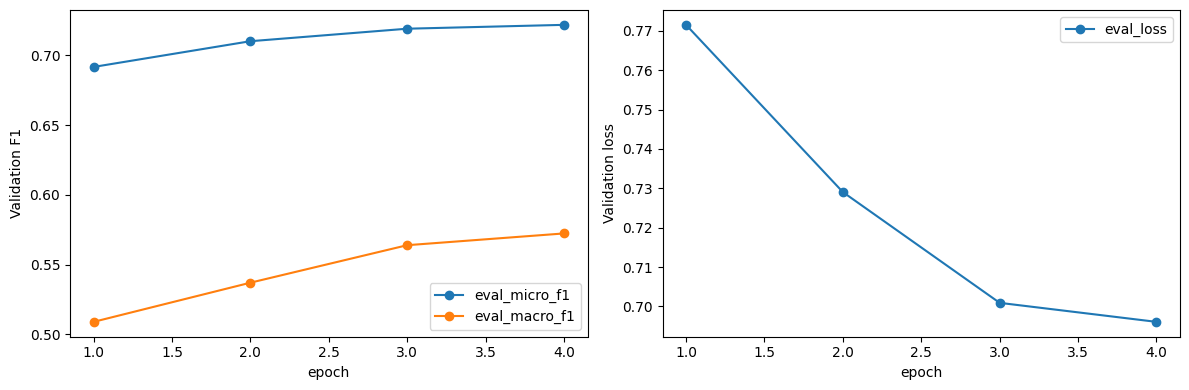

In [9]:
def evaluate_and_save(dataset,frame,prefix):
    output = trainer.predict(dataset,metric_key_prefix=prefix)
    predictions = np.argmax(output.predictions,axis=-1)
    labels = output.label_ids
    assert len(labels)==len(frame), 'Evaluation did not cover all rows.'
    names = [f'{i} star' for i in range(1,6)]
    print(classification_report(labels,predictions,labels=list(range(5)),
                                target_names=names,digits=4,zero_division=0))
    report = classification_report(labels,predictions,labels=list(range(5)),
        target_names=names,output_dict=True,zero_division=0)
    matrix = pd.DataFrame(confusion_matrix(labels,predictions,labels=list(range(5))),
        index=pd.Index(range(1,6),name='Actual'),
        columns=pd.Index(range(1,6),name='Predicted'))
    display(pd.DataFrame([output.metrics]))
    display(matrix)
    (RUN_DIR/f'{prefix}_metrics.json').write_text(json.dumps(output.metrics,indent=2))
    pd.DataFrame(report).T.to_csv(RUN_DIR/f'{prefix}_classification_report.csv')
    matrix.to_csv(RUN_DIR/f'{prefix}_confusion_matrix.csv')
    pd.DataFrame({'source_row_id':frame['source_row_id'].to_numpy(),
                  'actual_rating':labels+1,'predicted_rating':predictions+1
                 }).to_csv(RUN_DIR/f'{prefix}_predictions.csv',index=False)
    return output.metrics

best_validation_metrics = evaluate_and_save(tokenized_datasets['validation'],val_df,'validation')
summary = {
    'run_id':RUN_ID,'model':MODEL_NAME,'split_fingerprint':split_fingerprint,
    'max_length':MAX_LENGTH,'train_batch':TRAIN_BATCH_SIZE,
    'epochs_completed':trainer.state.epoch,
    'input_policy':'review_only_short__summary_head_tail_long',
    'effective_train_batch':TRAIN_BATCH_SIZE*GRADIENT_ACCUMULATION_STEPS,
    'peak_gpu_reserved_gb':peak_gpu_reserved_gb,
    'best_epoch':float(epoch_results.loc[epoch_results['eval_micro_f1'].idxmax(),'epoch']),
    'training_wall_seconds':elapsed_seconds,'peak_gpu_memory_gb':peak_gpu_memory_gb,
    **best_validation_metrics,
}
pd.DataFrame([summary]).to_csv(RUN_DIR/'comparison_row.csv',index=False)
display(pd.DataFrame([summary]))

import matplotlib.pyplot as plt
fig,axes = plt.subplots(1,2,figsize=(12,4))
epoch_results.plot(x='epoch',y=['eval_micro_f1','eval_macro_f1'],marker='o',ax=axes[0])
epoch_results.plot(x='epoch',y='eval_loss',marker='o',ax=axes[1])
axes[0].set_ylabel('Validation F1'); axes[1].set_ylabel('Validation loss')
fig.tight_layout()
fig.savefig(RUN_DIR/'validation_curves.png',dpi=150)
plt.show()


## ۸. Test نهایی — اختیاری
هنگام بررسی معماری‌ها خاموش بماند. پس از نهایی‌شدن تصمیم‌ها، RUN_TEST را True کنید و فقط این سلول را اجرا کنید. نتیجه Test برای انتخاب مدل، batch یا epoch استفاده نشود.


In [ ]:
if RUN_TEST:
    test_dataset = Dataset.from_pandas(test_df[['reviewText','summary','labels']],preserve_index=False)
    test_dataset = test_dataset.map(tokenize_batch,batched=True,batch_size=256,
                                    remove_columns=['reviewText','summary'],desc='Tokenizing final test')
    final_test_metrics = evaluate_and_save(test_dataset,test_df,'test')
else:
    print('Test evaluation is disabled. Use validation during model development.')


## ۹. پیش‌بینی یک متن جدید


In [11]:
def predict_rating(review_text, summary=''):
    if not isinstance(review_text,str) or not review_text.strip():
        raise ValueError('Please provide a non-empty review.')
    summary = '' if summary is None else str(summary)
    encoded = tokenize_batch({'reviewText':[review_text], 'summary':[summary]})
    example = {key:value[0] for key,value in encoded.items()}
    inputs = data_collator([example]).to(trainer.model.device)
    trainer.model.eval()
    with torch.inference_mode():
        probabilities = torch.softmax(trainer.model(**inputs).logits,dim=-1)[0].float().cpu().numpy()
    return {'predicted_rating':int(probabilities.argmax())+1,
            'input_tokens_without_batch_padding':len(example['input_ids']),
            'probabilities':{i+1:round(float(p),4) for i,p in enumerate(probabilities)}}

predict_rating('The headphones sound great and the battery lasts all day.',
               summary='Great headphones')


{'predicted_rating': 5,
 'input_tokens_without_batch_padding': 14,
 'probabilities': {1: 0.0017, 2: 0.0028, 3: 0.0125, 4: 0.0984, 5: 0.8847}}

## ۱۰. مقایسه با خط مبنای ۱۲۸ توکنی

اگر `BASELINE_RUN_DIR` تنظیم شده باشد، سلول بعد جدول مقایسه و تغییر معیارها را ذخیره می‌کند. در غیر این صورت مسیر فایل قبلی `comparison_row.csv` را در سلول بعد وارد کنید. برابری fingerprint تقسیم داده بررسی می‌شود. برای مقایسه از Validation استفاده کنید؛ Test برای تصمیم نهایی باقی می‌ماند.

Learning rate برای ثبت اثر تنظیمات در مقدار قبلی `2e-5` حفظ شده است. batch آموزش از ۳۲ به ۱۲۸ افزایش یافته؛ برای همان تعداد epoch تعداد optimizer stepها تقریباً یک‌چهارم است و برنامه learning rate نیز برحسب step تغییر می‌کند. این اجرا مقایسه دو پیکربندی کامل است. نسبت زمان زمانی معنی‌دارتر است که GPU و محیط اجرا مشابه و تعداد epochهای تکمیل‌شده برابر باشند؛ early stopping می‌تواند آن را تغییر دهد.

خروجی‌ها در پوشه مجزای اجرا ذخیره می‌شوند: معیارهای هر epoch، گزارش هر کلاس، confusion matrix، پیش‌بینی‌های validation، زمان، حافظه، تنظیمات، splitها، بهترین مدل و checkpointهای بهترین/آخرین epoch. برای استفاده از مدل ذخیره‌شده همان تابع `tokenize_batch` را با پارامترهای `input_preprocessing.json` اعمال کنید؛ truncation معمولی tokenizer قاعده head-tail را اجرا نمی‌کند.

مراجع: [Trainer 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer)، [BERT tokenizer](https://huggingface.co/docs/transformers/v4.57.1/en/model_doc/bert).


In [12]:
BASELINE_COMPARISON_CSV = (
    str(Path(BASELINE_RUN_DIR)/'comparison_row.csv') if BASELINE_RUN_DIR else None)
if BASELINE_COMPARISON_CSV:
    baseline = pd.read_csv(BASELINE_COMPARISON_CSV)
    current = pd.read_csv(RUN_DIR/'comparison_row.csv')
    assert len(baseline)==len(current)==1
    assert baseline.iloc[0]['split_fingerprint']==current.iloc[0]['split_fingerprint'], \
        'Different splits: rerun with REUSE_SPLITS_DIR pointing to the baseline splits.'
    baseline.insert(0,'experiment','baseline_128')
    current.insert(0,'experiment','summary_head_tail_256_batch128')
    comparison = pd.concat([baseline,current],ignore_index=True)
    columns = ['experiment','max_length','train_batch','epochs_completed',
               'validation_micro_f1','validation_macro_f1','validation_accuracy',
               'validation_mae','validation_loss','training_wall_seconds','peak_gpu_memory_gb']
    display(comparison[columns])
    comparison.to_csv(RUN_DIR/'baseline_vs_current.csv',index=False)
    for metric in ['validation_micro_f1','validation_macro_f1','validation_accuracy']:
        change = 100*(current.iloc[0][metric]-baseline.iloc[0][metric])
        print(f'{metric} change: {change:+.3f} percentage points')
    for metric in ['validation_mae','validation_loss']:
        change = current.iloc[0][metric]-baseline.iloc[0][metric]
        print(f'{metric} change: {change:+.4f} (negative means improvement)')
else:
    print('Set BASELINE_COMPARISON_CSV to compare with an existing baseline run.')


Set BASELINE_COMPARISON_CSV to compare with an existing baseline run.
